# 學生學習與作業版｜任務 1：讀取資料與定義問題

**姓名：王信昌**　**學號／組別：C114118145**　**完成日期：11/11**

**學習目標：** 認識 CSV、資料列與欄、資料字典，將寬泛問題轉成可回答的問題。

本單元與教師版「任務 1」相同標題、資料、教學順序與範例；除了明確標示的作業與填空，其餘教師版教材內容保留。對照重點：程式填空對應教師版「延伸實作：欄位選取」。

### 如何完成
1. 先閱讀觀念與執行資料準備；各單元可以獨立啟動，不需要依賴上一單元的變數。
2. **💻 P 作業**：在指定程式 cell 補上 `____`，可先用提供的 Vibe Coding 提示詞詢問 AI。補完再執行，並執行後面的驗證 cell。未填時出現 `NameError` 是預期現象，先完成填空再繼續。
3. **📝 Q 作業**：查詢 AI、比較教材內容，填寫緊接的文字作答區；請記錄實際提示詞、自己的解釋與查證方式。
4. **🎯 M 小任務**：在任務 4、8、12、16 將前面幾單元整合成可執行的成果。不要只交 AI 回覆，要交實際程式、輸出與自己的解釋。
5. 把 Notebook 存到自己的 Google 雲端硬碟，完成後下載／依教師指示繳交 `.ipynb`；小任務保留輸出、文字與 AI 使用紀錄。

**案例限制：**本資料是公式生成的 60 筆模擬紀錄，不能推論真實學生或因果。缺失與 15 小時值在計分後加入。預測時欄位可得性是假設；全部資料已在前半段探索，後續切出的測試集僅示範流程，不能視為完全獨立的新資料。

**完成檢核：**本單元有 1 項程式填空、2 項 AI 查詢作答；若是任務 4、8、12、16，另外有 1 項整合小任務。請保留自己的輸出、回答和驗證紀錄。


## 共用資料準備
以下在記憶體重建與既有教材相同的資料。執行後可以直接開始本單元；不會覆寫 CSV。


In [ ]:
# 匯入套件：numpy 建立隨機資料，pandas 管理表格，pyplot 繪圖
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 固定種子，並維持呼叫順序，以重現原教材的 60 筆模擬資料
rng = np.random.default_rng(42)
n = 60
departments = ["資訊管理", "企業管理", "金融管理"]
# 每個字典鍵是一個欄位；對應的值是 60 名學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)
# 成績依設定公式與隨機誤差建立；關係來自模擬規則，不能視為因果發現
noise = rng.normal(0, 5, n)
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)
# 故意在計分後加入資料品質問題；無法從表格還原計分時原始值
df.loc[[5, 17], "sleep_hours"] = np.nan
df.loc[8, "screen_time_hours"] = 15.0
print("模擬資料形狀（列, 欄）：", df.shape)


模擬資料形狀（列, 欄）： (60, 7)


## 1.1 從真實問題到資料表
**觀念說明：**一列是一個學生的模擬紀錄；欄位描述屬性。CSV 是純文字交換格式，DataFrame 是記憶體中的表格。`student_id` 雖是整數，仍是識別碼而非可以平均的量。

**提問：**`df.shape` 的第一個數與第二個數各代表什麼？

答 :

第一個數（60）：代表列數，即資料筆數。

第二個數（7）：代表欄數，即欄位數。


In [ ]:
# shape 依序回傳列數和欄數；head 讓我們預覽前 5 筆
print("資料筆數與欄位數：", df.shape)
print("欄位名稱：", list(df.columns))
display(df.head())
# dtypes 描述 pandas 儲存的型態，未必等於欄位的業務意義
print(df.dtypes)


資料筆數與欄位數： (60, 7)
欄位名稱： ['student_id', 'department', 'sleep_hours', 'screen_time_hours', 'study_hours', 'attendance_rate', 'quiz_score']


,student_id,department,sleep_hours,screen_time_hours,study_hours,attendance_rate,quiz_score
0,1,資訊管理,9.1,6.0,2.3,95.0,79.0
1,2,金融管理,6.3,4.9,1.5,77.0,74.0
2,3,企業管理,6.1,4.4,0.8,88.0,72.0
3,4,企業管理,5.8,4.9,2.0,84.0,85.0
4,5,企業管理,7.4,2.5,2.4,85.0,90.0


student_id             int64
department            object
sleep_hours          float64
screen_time_hours    float64
study_hours          float64
attendance_rate      float64
quiz_score           float64
dtype: object


## 📝 學生作業 01-Q1｜AI 查詢與作答：資料型態與欄位意義
**任務：**CSV 與 DataFrame 有什麼差異？student_id 為何雖是整數仍屬識別碼？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請用初學者能懂的例子比較 CSV 和 pandas DataFrame，並解釋以數字編碼的學生識別碼是否適合計算平均。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 01-Q1 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：Chatbox /
我是 Python 與資料分析初學者。請用初學者能懂的例子比較 CSV 和 pandas DataFrame，並解釋以數字編碼的學生識別碼是否適合計算平均。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。

- AI 回答重點（請自行整理）：

CSV檔案	是純文字、靜態、誰都能開,但不能直接吃（不能直接算平均、畫圖）
pandas DataFrame,已經切好塊、有標籤、拿起刀叉（程式碼）就能直接分析。

學生識別碼不適合計算平均，因為學號 (1001、1002、1003)就像座位號、身分證字號、電話號碼，平均之後（1001+1002+1003）/3 = 1002 ，完全沒有實際意義。


- 我的理解與具體例子：

理解:

CSV是儲存在硬碟上，以純文字進行存放，可透過記事本、Excel、VS Code開啟，但是不能直接計算平均值，需要先匯入軟體，修改後還需另存新檔才能寫回硬碟裡。
而DataFrame則是儲存在記憶體裡，運用欄、列把資料去進行分類存放，可透過Python程式開啟，還能透過df["sleep_hours"].mean() 計算平均，修改後也不需像CSV另存新檔寫回硬碟，而是只改記憶體中的資料就好，但是如果下次開機還能用，一定要呼叫 df.to_csv(...) 寫回硬碟，才能永久保存。

數字適不適合算平均，看的是『這個數字代表的是「數量」還是「標籤」』。

具體例子：

睡眠 6.5、7.0、8.5 → 代表實際睡了幾個鐘頭，平均 7.33 小時是有意義的，可以說「這班平均睡 7.33 小時」。



- 查證來源／方式及日期（無法查證請註明）：無法查證(未提供)
- 我檢查或修正 AI 回答的地方：pd.read_csv() 本身不會修改資料值，只是把文字解析成記憶體結構；真正的「處理/清洗」通常發生在 讀完之後



## 1.2 建立資料字典
**觀念說明：**單位與欄位意義影響解讀；`attendance_rate` 使用 0～100 的百分比，不是 0～1。成績和各行為的關係是人為寫入，不能宣稱是因果。

**驗證：**欄位數是否與資料字典一致？每個時間欄位的單位是否清楚？


In [ ]:
# 建立簡單資料字典：讓其他人知道每個欄位代表什麼
dictionary = pd.DataFrame({
    "column": list(df.columns),
    "meaning": ["學生編號", "科系", "睡眠時間", "螢幕時間", "讀書時間", "出席率", "小考成績"],
    "unit": ["識別碼", "類別", "小時", "小時", "小時", "%", "分"]
})
display(dictionary)
assert len(dictionary) == df.shape[1]  # 驗證資料字典沒有漏列欄位


,column,meaning,unit
0,student_id,學生編號,識別碼
1,department,科系,類別
2,sleep_hours,睡眠時間,小時
3,screen_time_hours,螢幕時間,小時
4,study_hours,讀書時間,小時
5,attendance_rate,出席率,%
6,quiz_score,小考成績,分


## 📝 學生作業 01-Q2｜AI 查詢與作答：把問題寫清楚
**任務：**將「學習狀況好不好」改寫為可用現有欄位回答的問題，並寫出一個無法由本資料回答的問題。

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。我有 student_id、department、study_hours、sleep_hours、quiz_score 等欄位。請提供可回答與不能回答的各一個研究問題，說明理由，不要編造資料。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 01-Q2 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：Chatbox /我是 Python 與資料分析初學者。我有 student_id、department、study_hours、sleep_hours、quiz_score 等欄位。請提供可回答與不能回答的各一個研究問題，說明理由，不要編造資料。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。

- AI 回答重點（請自行整理）：

能回答的研究問題範例:

問題 A：資管系學生的平均讀書時數，是否比企管系與金管系高？

理由1:變項都在表裡？

department (分群) + study_hours (結果)

理由2:統計方法存在？

單因子變異數分析 (One-way ANOVA) 或 Kruskal-Wallis

理由3:結論範圍合理？

只能說「這 60 位學生中，資管系樣本平均較高」，不能推論「資管系課業較重」或「讀書多導致分數高」

不能回答的研究問題範例:

問題 B：如果強迫學生每天多睡 1 小時，小考成績會上升幾分？

理由1:反事實缺失

我們只觀察「自然睡 6 小時的人考 70 分」與「自然睡 7 小時的人考 75 分」，沒有同一個人在「被迫多睡 1 小時」下的分數

理由2:混淆變項

也許「成績好 → 心情好 → 睡得久」，或「作息自律 → 又愛讀書又愛早睡」

理由3:模擬資料非真實

教材已說明：分數是公式+亂數產生，人為寫入 2×sleep_hours，非真實因果


- 我的理解與具體例子：

例子：把「能回答」的問題 A 換成 sleep_hours 或 quiz_score，重跑一次群體比較。

sleep_hours的統計結果完全無差異，代表符合生成機制（隨機指派），驗證「隨機化成功」。

quiz_score的統計結果數值有落差、統計不顯著，代表這是抽樣誤差導致的「假象」，從而得知p-value ≠ 實質重要性和樣本數與統計力的關係。


- 查證來源／方式及日期（無法查證請註明）：無法查證(未提供)


- 我檢查或修正 AI 回答的地方：

檢查把「能回答」的問題 A 換成 sleep_hours 或 quiz_score，重跑一次群體比較，AI回應的結果。


🎯 群體比較：sleep_hours ~ department
            count  mean   std  median
department                           
企業管理           21  6.56  0.81     6.4
資訊管理           14  6.75  1.04     6.8
金融管理           23  6.75  0.70     6.9


/tmp/ipykernel_1056/4178957629.py:27: UserWarning: Glyph 36039 (\N{CJK UNIFIED IDEOGRAPH-8CC7}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1056/4178957629.py:27: UserWarning: Glyph 35338 (\N{CJK UNIFIED IDEOGRAPH-8A0A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1056/4178957629.py:27: UserWarning: Glyph 31649 (\N{CJK UNIFIED IDEOGRAPH-7BA1}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1056/4178957629.py:27: UserWarning: Glyph 29702 (\N{CJK UNIFIED IDEOGRAPH-7406}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1056/4178957629.py:27: UserWarning: Glyph 37329 (\N{CJK UNIFIED IDEOGRAPH-91D1}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1056/4178957629.py:27: UserWarning: Glyph 34701 (\N{CJK UNIFIED IDEOGRAPH-878D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1056/4178957629.py:27: UserWarning: Glyph 20225 (\N{CJK UNIFIED IDEOGRAPH-4F01}

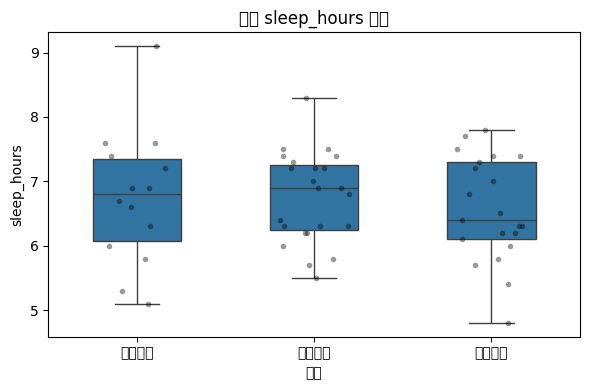


--- 常態性檢定 (Shapiro-Wilk) ---
  企業管理  : W=0.962, p=0.560 ✅常態
  資訊管理  : W=0.965, p=0.809 ✅常態
  金融管理  : W=0.962, p=0.496 ✅常態

--- 等變異數檢定 ---
  Levene: stat=0.667, p=0.518 ✅等變異

--- 群體差異檢定 ---
  One-way ANOVA: F=0.347, p=0.7081 ❌無顯著差異
  Kruskal-Wallis: H=0.385, p=0.8247 ❌無顯著差異

  (ANOVA 不顯著，略過事後比較)

🎯 群體比較：quiz_score ~ department
            count   mean   std  median
department                            
企業管理           21  80.67  7.25    81.0
資訊管理           15  79.73  4.13    80.0
金融管理           24  76.58  7.03    76.5


/tmp/ipykernel_1056/4178957629.py:27: UserWarning: Glyph 36039 (\N{CJK UNIFIED IDEOGRAPH-8CC7}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1056/4178957629.py:27: UserWarning: Glyph 35338 (\N{CJK UNIFIED IDEOGRAPH-8A0A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1056/4178957629.py:27: UserWarning: Glyph 31649 (\N{CJK UNIFIED IDEOGRAPH-7BA1}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1056/4178957629.py:27: UserWarning: Glyph 29702 (\N{CJK UNIFIED IDEOGRAPH-7406}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1056/4178957629.py:27: UserWarning: Glyph 37329 (\N{CJK UNIFIED IDEOGRAPH-91D1}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1056/4178957629.py:27: UserWarning: Glyph 34701 (\N{CJK UNIFIED IDEOGRAPH-878D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1056/4178957629.py:27: UserWarning: Glyph 20225 (\N{CJK UNIFIED IDEOGRAPH-4F01}

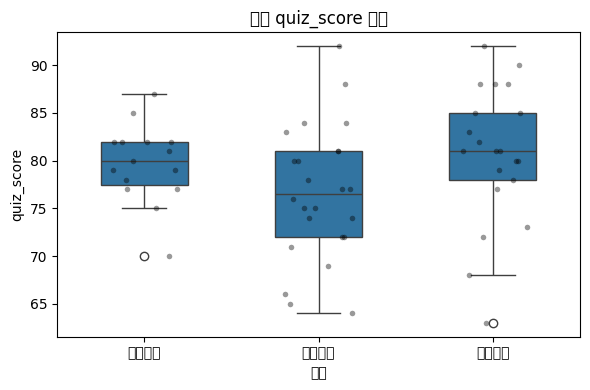


--- 常態性檢定 (Shapiro-Wilk) ---
  企業管理  : W=0.953, p=0.384 ✅常態
  資訊管理  : W=0.960, p=0.684 ✅常態
  金融管理  : W=0.985, p=0.966 ✅常態

--- 等變異數檢定 ---
  Levene: stat=1.798, p=0.175 ✅等變異

--- 群體差異檢定 ---
  One-way ANOVA: F=2.395, p=0.1003 ❌無顯著差異
  Kruskal-Wallis: H=5.255, p=0.0723 ❌無顯著差異

  (ANOVA 不顯著，略過事後比較)


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

# 若你的 df 已經在記憶體中，直接執行下面即可；
# 若是新啟動的 notebook，請先跑過「共用資料準備」那一段建立 df。

targets = ["sleep_hours", "quiz_score"]   # 要比較的兩個因變項

for target in targets:
    print(f"\n{'='*50}")
    print(f"🎯 群體比較：{target} ~ department")
    print(f"{'='*50}")

    # 1️⃣ 描述統計
    desc = df.groupby("department")[target].agg(["count", "mean", "std", "median"])
    print(desc.round(2))

    # 2️⃣ 箱鬚圖 + 條狀圖（疊加原始點）
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df, x="department", y=target, showcaps=True, width=0.5)
    sns.stripplot(data=df, x="department", y=target, color="black", alpha=0.4, size=4, jitter=0.2)
    plt.title(f"各系 {target} 分布")
    plt.xlabel("科系")
    plt.ylabel(target)
    plt.tight_layout()
    plt.show()

    # 3️⃣ 常態性檢定（Shapiro-Wilk，各組樣本數 < 50 適合）
    print("\n--- 常態性檢定 (Shapiro-Wilk) ---")
    for dept, group in df.groupby("department"):
        stat, p = stats.shapiro(group[target].dropna())
        print(f"  {dept:6s}: W={stat:.3f}, p={p:.3f} {'✅常態' if p > 0.05 else '❌非常態'}")

    # 4️⃣ 等變異數檢定
    print("\n--- 等變異數檢定 ---")
    groups = [g[target].dropna().values for _, g in df.groupby("department")]
    # Levene 對常態性不敏感，建議優先使用
    stat, p = stats.levene(*groups)
    print(f"  Levene: stat={stat:.3f}, p={p:.3f} {'✅等變異' if p > 0.05 else '❌異質性'}")

    # 5️⃣ 統計檢定
    print("\n--- 群體差異檢定 ---")
    # ANOVA（參數檢定）
    stat_a, p_a = stats.f_oneway(*groups)
    print(f"  One-way ANOVA: F={stat_a:.3f}, p={p_a:.4f} {'✅有顯著差異' if p_a < 0.05 else '❌無顯著差異'}")
    # Kruskal-Wallis（非參數檢定，不假設常態）
    stat_k, p_k = stats.kruskal(*groups)
    print(f"  Kruskal-Wallis: H={stat_k:.3f}, p={p_k:.4f} {'✅有顯著差異' if p_k < 0.05 else '❌無顯著差異'}")

    # 6️⃣ 事後比較（若 p < 0.05 才有意義，這裡示範 Tukey HSD）
    if p_a < 0.05:
        print("\n--- 事後比較 Tukey HSD ---")
        from statsmodels.stats.multicomp import pairwise_tukeyhsd
        tukey = pairwise_tukeyhsd(df[target].dropna(),
                                  df.loc[df[target].notna(), "department"])
        print(tukey.summary())
    else:
        print("\n  (ANOVA 不顯著，略過事後比較)")


## 1.3 CSV 讀寫與問題定義
本示範使用記憶體中的文字緩衝區，不寫檔。若要使用教材包中的 `student_learning_data.csv`，請先上傳 Colab，再執行 `pd.read_csv("student_learning_data.csv")`。不要將教師電腦的絕對路徑直接放進教材。

**課堂任務：**將「學習狀況好嗎？」改為「讀書時數與小考成績在這份模擬資料中有何關係？」標明所需欄位和無法回答的因果問題。


In [ ]:
from io import StringIO
# 使用字串緩衝區示範 CSV 序列化與讀取；index=False 不把列索引存成資料欄
buffer = StringIO()
df.to_csv(buffer, index=False)
buffer.seek(0)  # 將讀取位置移回開頭
loaded = pd.read_csv(buffer)
print("讀回形狀：", loaded.shape)
print("欄位相同：", list(loaded.columns) == list(df.columns))
print("睡眠缺失筆數：", loaded["sleep_hours"].isna().sum())


讀回形狀： (60, 7)
欄位相同： True
睡眠缺失筆數： 2


## 延伸實作：欄位選取與問題能否回答
**講解：**`df["study_hours"]` 選一欄；雙層中括號選多欄並保留表格。先問資料是否具有回答問題所需的欄位，而不是立刻畫圖。

**提問與參考方向：**能否回答「讀書時數較高的人分數是否較高」？可描述模擬資料的關係；能否回答「多讀一小時是否造成成績提升」？不能只靠觀察資料與此公式生成資料確立因果。

**AI 提示詞：**請以初學者語言解釋 pandas 選取一欄與多欄，並設計不修改原表的驗證。


## 💻 學生作業 01-P1｜Vibe Coding 程式填空
**對應教師版：**任務 1「延伸實作：欄位選取」的示範程式。

**任務：**從 df 選出 student_id、study_hours、quiz_score 三欄，儲存為 selected_columns，不改動 df。

**執行方式：**找到下一個程式儲存格中的 `____`，使用自己撰寫或 AI 建議的程式補齊，保留其他已提供的程式與註解。補完後先執行該 cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。

**可使用的 Vibe Coding 提示詞：**
```text
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：從 df 選出 student_id、study_hours、quiz_score 三欄，儲存為 selected_columns，不改動 df。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
```
完成後記錄實際使用的提示詞與自己改動的地方。


In [ ]:
# 單欄通常得到 Series；多欄清單得到 DataFrame
study_column = df["study_hours"]

# TODO：選取三欄，保留 DataFrame
# 使用雙層方括號：外層是索引運算子，內層是「欄位名稱清單」
# 這會回傳新的 DataFrame（視圖或副本），不會修改原始 df
selected_columns = df[["student_id", "study_hours", "quiz_score"]]

print("單欄型態：", type(study_column).__name__)
print("多欄形狀：", selected_columns.shape)
display(selected_columns.head())
assert len(selected_columns) == len(df)


單欄型態： Series
多欄形狀： (60, 3)


,student_id,study_hours,quiz_score
0,1,2.3,79.0
1,2,1.5,74.0
2,3,0.8,72.0
3,4,2.0,85.0
4,5,2.4,90.0


### ✅ 作業 01-P1｜執行驗證
執行下方程式，並同時檢查上方實際輸出。自動檢查只涵蓋主要條件；如果圖表、說明或資料來源不符任務，仍需人工修正。


In [ ]:
assert list(selected_columns.columns) == ["student_id", "study_hours", "quiz_score"]
assert len(selected_columns) == len(df)
print("檢查通過：欄位順序與筆數正確。")


檢查通過：欄位順序與筆數正確。


### ✍️ 作業 01-P1｜我的完成紀錄
- 我實際使用的提示詞（若未使用 AI 請註明）：

我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：從 df 選出 student_id、study_hours、quiz_score 三欄，儲存為 selected_columns，不改動 df。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
- 我補上的程式在做什麼：

取多欄位 → DataFrame
- 執行或驗證遇到的問題與修正：

錯誤:df["student_id", "study_hours", "quiz_score"] → KeyError，單層括號只接受單一鍵值（或切片），不接受 tuple/list。

修正:df[["student_id", "study_hours", "quiz_score"]] → 雙層括號 = 「傳入一個 list 作為索引器」

- 檢查結果及我如何確認：跑完若形狀是 (60, 3)、欄位順序正確，就代表選取成功！


## 本單元學習收束與 AI 使用紀錄

請學生先用自己的話解釋一個關鍵觀念，再指出一個執行結果及驗證方式。記錄：使用的提示詞、AI 回答中檢查或修改的地方、遇到的問題、修正後的證據與本資料限制。

**通用提示詞**：我是 Python 初學者，請逐步協助我完成上面的任務；每段程式加繁體中文註解，說明輸入、處理與輸出，提供兩項可實際執行的驗證，保留原始資料，不要虛構執行結果。


這裡將任務拆解為 三個小步驟，每步皆附上「輸入 → 處理 → 輸出」註解，並在最後提供 兩項你可以在 Colab 實際執行的驗證程式碼。
請依順序複製到三個獨立儲存格（Cell）執行，即可完成並驗證。

步驟 1️⃣ 先看原始資料長什麼樣（建立基準）

In [ ]:
# 【輸入】原始 DataFrame df（記憶體中已存在）
# 【處理】檢視欄位名稱、前 3 列、形狀
# 【輸出】在 Notebook 印出清單與表格，供肉眼確認
print("原始欄位清單：", df.columns.tolist())
print("原始形狀（列, 欄）：", df.shape)
display(df.head(3))   # 只看前 3 列即可


原始欄位清單： ['student_id', 'department', 'sleep_hours', 'screen_time_hours', 'study_hours', 'attendance_rate', 'quiz_score']
原始形狀（列, 欄）： (60, 7)


,student_id,department,sleep_hours,screen_time_hours,study_hours,attendance_rate,quiz_score
0,1,資訊管理,9.1,6.0,2.3,95.0,79.0
1,2,金融管理,6.3,4.9,1.5,77.0,74.0
2,3,企業管理,6.1,4.4,0.8,88.0,72.0


步驟 2️⃣ 選取三欄並存入新變數 selected_columns

In [ ]:
# 【輸入】原始 df、欲保留的欄位名稱清單
# 【處理】使用「雙層方括號」df[[...]] 依指定順序取出多欄
#        → 回傳「新的 DataFrame」（不動原始 df）
# 【輸出】指派給變數 selected_columns，供下游使用
selected_columns = df[["student_id", "study_hours", "quiz_score"]]


步驟 3️⃣ 立即做兩項「可實際執行的驗證」

驗證 A：結構正確性（型別、形狀、欄位順序）

In [ ]:
# 【驗證 A】結構正確性
# 輸入：selected_columns
# 處理：檢查型別、形狀、欄位順序
# 輸出：印出結果供人工比對
print("✅ 驗證 A ── 結構正確性")
print("  型別：", type(selected_columns).__name__)        # 預期 DataFrame
print("  形狀：", selected_columns.shape)                 # 預期 (60, 3)
print("  欄位順序：", selected_columns.columns.tolist())  # 預期 ['student_id', 'study_hours', 'quiz_score']


✅ 驗證 A ── 結構正確性
  型別： DataFrame
  形狀： (60, 3)
  欄位順序： ['student_id', 'study_hours', 'quiz_score']


驗證 B：資料完整性（列數一致、前幾筆值正確、原始 df 未變）

In [ ]:
# 【驗證 B】資料完整性
# 輸入：selected_columns、原始 df
# 處理：比對列數、抽樣檢視、確認 df 未被修改
# 輸出：印出比對結果
print("\n✅ 驗證 B ── 資料完整性")

# 1. 列數是否相同
print("  列數一致？", len(selected_columns) == len(df))   # 預期 True

# 2. 抽樣看前 3 列資料值
display(selected_columns.head(3))

# 3. 確認原始 df 仍保有 7 欄、未被刪減
print("  原始 df 欄位數未變？", df.shape[1] == 7)         # 預期 True
print("  原始 df 仍有 department？", "department" in df.columns)  # 預期 True



✅ 驗證 B ── 資料完整性
  列數一致？ True


,student_id,study_hours,quiz_score
0,1,2.3,79.0
1,2,1.5,74.0
2,3,0.8,72.0


  原始 df 欄位數未變？ True
  原始 df 仍有 department？ True
